# Прочтение и обработка данных

Скачиваем основные библиотеки и закружаем ESMC 300m (надеюсь, она потянет кластеризацию, с моделями 600m и выше мой компьютер можеть не справиться)

In [7]:
import torch
import numpy as np
import matplotlib
import umap
import sklearn
from esm.models.esmc import ESMC
import esm

# Настройка устройства
device = "cpu"
print(f"Используем: {device}")

# Загрузка ESMC модели
client = ESMC.from_pretrained("esmc_300m").to(device)
client.eval()
print("Модель ESMC загружена.")

Используем: cpu


Fetching 4 files: 100%|██████████| 4/4 [00:00<00:00, 572.91it/s]


Модель ESMC загружена.


Подружить версии библиотек между собой было сложно, вот ячейка с проверкой их версий 

In [8]:
import sys
print(sys.executable)
def check_versions():
    print("Проверка версий библиотек:")
    print(f"Python: {sys.version.split()[0]}")
    print(f"torch: {torch.__version__}")
    print(f"numpy: {np.__version__}")
    print(f"matplotlib: {matplotlib.__version__}")
    print(f"umap: {umap.__version__}")
    print(f"sklearn: {sklearn.__version__}")
    print(f"esm: {esm.__version__}")
    
    # Проверка совместимости версий
    if not torch.cuda.is_available():
        print("\nВнимание: CUDA не доступна. Будет использоваться CPU.")
    
    print("\nВсе версии проверены. Можно продолжать работу.")

# Запустить проверку
check_versions()

C:\Users\Lenovo\anaconda3\envs\torch_esm\python.exe
Проверка версий библиотек:
Python: 3.10.22
torch: 2.14.1+cpu
numpy: 1.26.4
matplotlib: 3.10.9
umap: 0.5.12
sklearn: 1.7.2
esm: 3.2.1

Внимание: CUDA не доступна. Будет использоваться CPU.

Все версии проверены. Можно продолжать работу.


Докачиваем доп библиотеки

In [9]:
import requests
from esm.models.esmc import ESMC
from esm.sdk.api import ESMProtein, LogitsConfig
from io import StringIO

In [10]:
# Функция загрузки FASTA из URL, тк мой датасет лежит по ссылке
def load_fasta_from_url(url):
    response = requests.get(url)
    response.raise_for_status()
    return StringIO(response.text)
# Функция парсинга FASTA
def parse_fasta(file_content):
    records = []
    current_id = None
    current_seq = []
    
    for line in file_content:
        line = line.strip()
        if not line:
            continue
        if line.startswith(">"):
            if current_id is not None and current_seq:
                records.append((current_id, "".join(current_seq)))
            current_id = line[1:]
            current_seq = []
        else:
            current_seq.append(line)
    if current_id is not None and current_seq:
        records.append((current_id, "".join(current_seq)))
    return records

Прочтение файла №1

In [11]:
DATASET_URL = "https://raw.githubusercontent.com/gordeyAI/Main/main/Dataset%20Cas12_TnpB.txt"
fasta_content = load_fasta_from_url(DATASET_URL)
sequences = parse_fasta(fasta_content)
print(f"Загружено последовательностей: {len(sequences)}")

Загружено последовательностей: 17


In [21]:
# Фильтрация последовательностей
filtered_sequences = []
labels = []
for prot_id, seq in sequences:
    if "Cas12" in prot_id:
        filtered_sequences.append((prot_id, seq))
        labels.append("Cas12")
    elif "TnpB" in prot_id:
        filtered_sequences.append((prot_id, seq))
        labels.append("TnpB")
print(f"Отфильтровано последовательностей: {len(filtered_sequences)}")
for i, (prot_id, seq) in enumerate(filtered_sequences):
    print(f"ID: {prot_id}")
    print(f"Длина последовательности: {len(seq)}")
    print(f"Начало последовательности: {seq[:20]}...")
    print("-" * 40)

Отфильтровано последовательностей: 17
ID: WP_510591476.1 type V CRISPR-associated protein Cas12a/Cpf1 [Lachnospira eligens]
Длина последовательности: 1282
Начало последовательности: MNGNRSIVYREFVGVIPVAK...
----------------------------------------
ID: WP_048112740.1 type V CRISPR-associated protein Cas12a/Cpf1 [Candidatus Methanoplasma termitum]
Длина последовательности: 1238
Начало последовательности: MNNYDEFTKLYPIQKTIRFE...
----------------------------------------
ID: sp|A0Q7Q2.1|CS12A_FRATN RecName: Full=CRISPR-associated endonuclease Cas12a; AltName: Full=CRISPR-associated endonuclease Cpf1; AltName: Full=FnCas12a; AltName: Full=FnCpf1
Длина последовательности: 1300
Начало последовательности: MSIYQEFVNKYSLSKTLRFE...
----------------------------------------
ID: WP_488761216.1 type V CRISPR-associated protein Cas12a/Cpf1 [Moraxella bovoculi]
Длина последовательности: 685
Начало последовательности: MNKEKDNFGVILQKDGCYYL...
----------------------------------------
ID: sp|A0A482D308.1|CS1

# Построение и подготовка эмбеддингов. Кластеризация тренировочной выборки

In [30]:
#Построение эмбеддингов и их сжатие
def get_embedding(sequence):
    protein = ESMProtein(sequence=sequence)
    protein_tensor = client.encode(protein)
    with torch.no_grad():
        output = client.logits(
            protein_tensor,
            LogitsConfig(sequence=True, return_embeddings=True)
        )
    emb_tensor = output.embeddings[0]
    vec = emb_tensor.mean(dim=0)
    return vec.cpu().numpy()
embeddings = []
for _, seq in filtered_sequences:
    embeddings.append(get_embedding(seq))
    print(f"embedding {len(embeddings)} complete")
X = np.array(embeddings)

embedding 1 complete
embedding 2 complete
embedding 3 complete
embedding 4 complete
embedding 5 complete
embedding 6 complete
embedding 7 complete
embedding 8 complete
embedding 9 complete
embedding 10 complete
embedding 11 complete
embedding 12 complete
embedding 13 complete
embedding 14 complete
embedding 15 complete
embedding 16 complete
embedding 17 complete


С помощью umap можно преобразовать имеющиеся эмбеддинги в вектора длиной 2000, как вы и сказали. Но кластеризация работает и без этого, поэтому для пилотной версии в этой функции нет необходимости

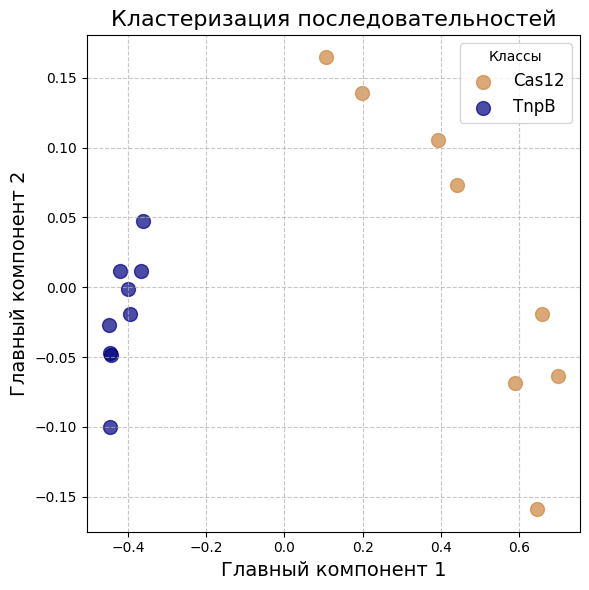

In [24]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import LabelEncoder
#Увеличение размерности до 2д для кластеризации
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)
# Кодируем метки
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(labels)

# Создаем цветовую палитру
unique_labels = np.unique(y)
colors=['peru','navy']

# Строим график
plt.figure(figsize=(6,6))
proteins = ['Cas12','TnpB']
# Рисуем точки
for i, color in zip(unique_labels, colors):
    plt.scatter(
        X_pca[y == i, 0],
        X_pca[y == i, 1],
        label=f'{proteins[i]}',
        alpha=0.7,
        s=100,
        c=[color]
    )

# Добавляем элементы оформления
plt.title('Кластеризация последовательностей', fontsize=16)
plt.xlabel('Главный компонент 1', fontsize=14)
plt.ylabel('Главный компонент 2', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(title='Классы', fontsize=12)
plt.tight_layout()

# Сохраняем график
plt.savefig('cluster_visualization.png', dpi=300)
plt.show()

B ncbi не было нативного Cas12j, поэтому его в тренировочную выборку не включал

# На основании датасета тренирую классификатор

In [25]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# Используем все данные из файла 1 для обучения
X_train = X  # Все эмбеддинги
y_train = y  # Все метки

# Создаем и обучаем классификатор
classifier = RandomForestClassifier(n_estimators=100, random_state=42)
classifier.fit(X_train, y_train)

# Функция для предсказания класса новой последовательности
def predict_protein_class(sequence):
    embedding = get_embedding(sequence)
    prediction = classifier.predict([embedding])
    return label_encoder.inverse_transform(prediction)[0]

# Работа алгоритма на примере тестовой выборки, где уже не только wp и sp

In [28]:
# Функция для загрузки тестового датасета
TEST_URL = "https://raw.githubusercontent.com/gordeyAI/Main/main/test%20TnpB%20%D0%B8%20Cas12.txt"
test_fasta_content = load_fasta_from_url(TEST_URL)
test_sequences = parse_fasta(test_fasta_content)

In [31]:
# Подготовка тестовых данных
test_filtered_sequences = []
test_labels = []
for prot_id, seq in test_sequences:
    if "Cas12" in prot_id:
        test_filtered_sequences.append((prot_id, seq))
        test_labels.append("Cas12")
    elif "TnpB" in prot_id:
        test_filtered_sequences.append((prot_id, seq))
        test_labels.append("TnpB")

# Получение эмбеддингов для тестовых данных
test_embeddings = []
for _, seq in test_filtered_sequences:
    test_embeddings.append(get_embedding(seq))
    print(f"Тестовый embedding {len(test_embeddings)} готов")

X_test = np.array(test_embeddings)
y_test = label_encoder.transform(test_labels)

Тестовый embedding 1 готов
Тестовый embedding 2 готов
Тестовый embedding 3 готов
Тестовый embedding 4 готов
Тестовый embedding 5 готов
Тестовый embedding 6 готов
Тестовый embedding 7 готов
Тестовый embedding 8 готов


Отчёт классификации:
              precision    recall  f1-score   support

           0       0.80      1.00      0.89         4
           1       1.00      0.75      0.86         4

    accuracy                           0.88         8
   macro avg       0.90      0.88      0.87         8
weighted avg       0.90      0.88      0.87         8



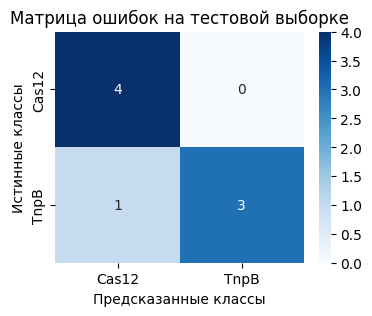

In [33]:
# Предсказание классов
y_pred = classifier.predict(X_test)
# Оценка качества
print("Отчёт классификации:")
print(classification_report(y_test, y_pred))

# Матрица ошибок
plt.figure(figsize=(4, 3))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(
    cm, 
    annot=True, 
    fmt='d', 
    cmap='Blues',
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.title('Матрица ошибок на тестовой выборке')
plt.xlabel('Предсказанные классы')
plt.ylabel('Истинные классы')
plt.show()

точность довольно высокая, можно еще увеличить ее, если сделать эмбеддинги длины 2000 или 16000